# Modellierung

## Init

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path)

# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Datenselektierung

In [3]:
# Prepare features and target
X = df[['calls', 'n_duty', 'n_sby', 'sby_need', 'dafted', 'month', 'day_of_week']]
y = df['n_sick']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modellierungvergleiche

In [4]:

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Support Vector Machine': SVR(),
    'K-Nearest Neighbors': KNeighborsRegressor(),
    'Neural Network': MLPRegressor(random_state=42, max_iter=1000),
    'Lasso Regression': Lasso(random_state=42),
    'Ridge Regression': Ridge(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

# Train and evaluate each model
results = {}
for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results[model_name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}
    print(f'{model_name} - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}')


Linear Regression - MAE: 9.661980111585619, MSE: 142.4235894504333, RMSE: 11.934135471429562, R2: 0.3694563940110758
Decision Tree - MAE: 9.941558441558442, MSE: 158.28246753246754, RMSE: 12.581036027786723, R2: 0.2992453130281414
Random Forest - MAE: 7.693878169449599, MSE: 96.79948436705733, RMSE: 9.838672896638922, R2: 0.571445319092208
Gradient Boosting - MAE: 7.321729724000432, MSE: 84.56159656254479, RMSE: 9.195737956387447, R2: 0.6256254021509258
Support Vector Machine - MAE: 12.121095540161607, MSE: 221.1608863733094, RMSE: 14.871478957161907, R2: 0.02086737642526837
K-Nearest Neighbors - MAE: 11.314285714285711, MSE: 194.90735930735934, RMSE: 13.960922580809598, R2: 0.1370980773222792
Neural Network - MAE: 11.29958762663721, MSE: 186.7758638563714, RMSE: 13.666596644972419, R2: 0.17309817030921293
Lasso Regression - MAE: 9.695712402546384, MSE: 144.27307867305603, RMSE: 12.011372888769046, R2: 0.36126825882806224
Ridge Regression - MAE: 9.662007061717013, MSE: 142.425414527293

Models sorted by MAE:
                              MAE         MSE       RMSE        R2
Gradient Boosting        7.321730   84.561597   9.195738  0.625625
Random Forest            7.693878   96.799484   9.838673  0.571445
XGBoost                  8.062496  106.532446  10.321456  0.528355
Linear Regression        9.661980  142.423589  11.934135  0.369456
Ridge Regression         9.662007  142.425415  11.934212  0.369448
Lasso Regression         9.695712  144.273079  12.011373  0.361268
Decision Tree            9.941558  158.282468  12.581036  0.299245
Neural Network          11.299588  186.775864  13.666597  0.173098
K-Nearest Neighbors     11.314286  194.907359  13.960923  0.137098
Support Vector Machine  12.121096  221.160886  14.871479  0.020867


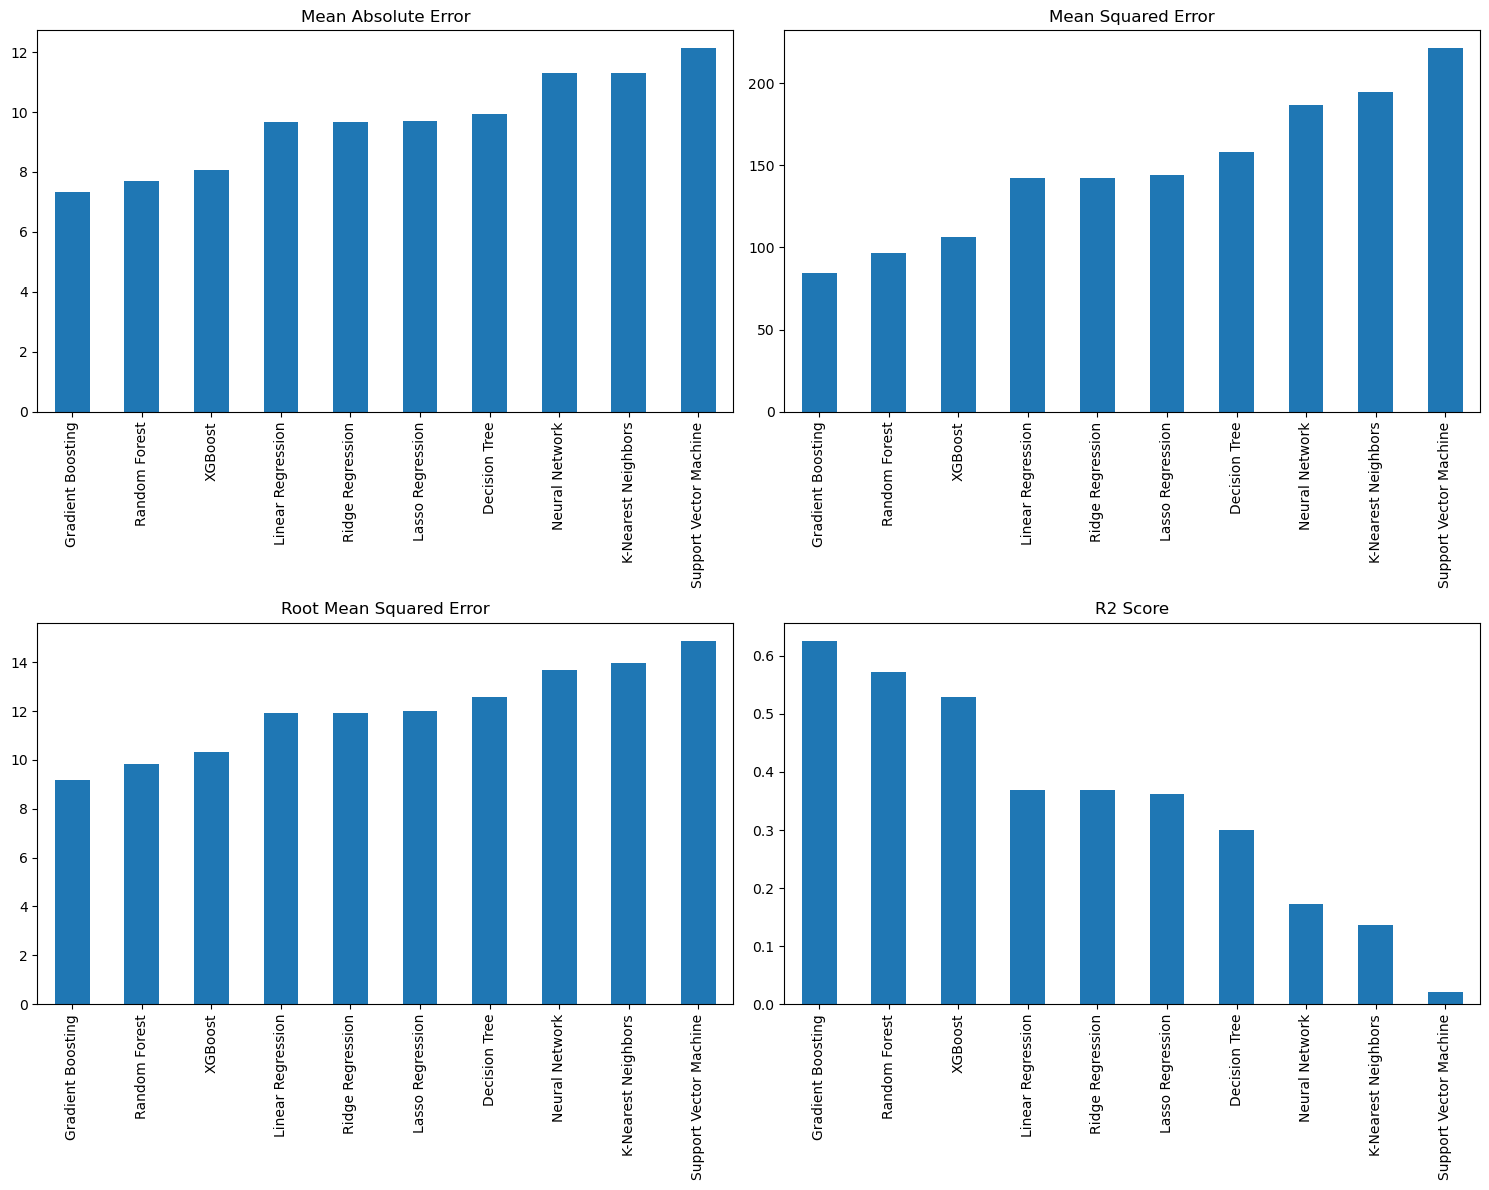

In [5]:
# Convert results to a DataFrame for easier comparison
results_df = pd.DataFrame(results).T

# Sort the models by MAE (you can change the metric to sort by other scores)
results_df_sorted = results_df.sort_values(by='MAE')

print("Models sorted by MAE:")
print(results_df_sorted)

# Visualize the results
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
results_df_sorted['MAE'].plot(kind='bar', ax=axes[0, 0], title='Mean Absolute Error')
results_df_sorted['MSE'].plot(kind='bar', ax=axes[0, 1], title='Mean Squared Error')
results_df_sorted['RMSE'].plot(kind='bar', ax=axes[1, 0], title='Root Mean Squared Error')
results_df_sorted['R2'].plot(kind='bar', ax=axes[1, 1], title='R2 Score')
plt.tight_layout()
plt.show()

In [6]:
# Select the best model based on MAE
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)

Best Model: Gradient Boosting
MAE      7.321730
MSE     84.561597
RMSE     9.195738
R2       0.625625
Name: Gradient Boosting, dtype: float64


Final Evaluation of the Best Model (Gradient Boosting):
MAE: 7.321729724000432, MSE: 84.56159656254479, RMSE: 9.195737956387447, R2: 0.6256254021509258


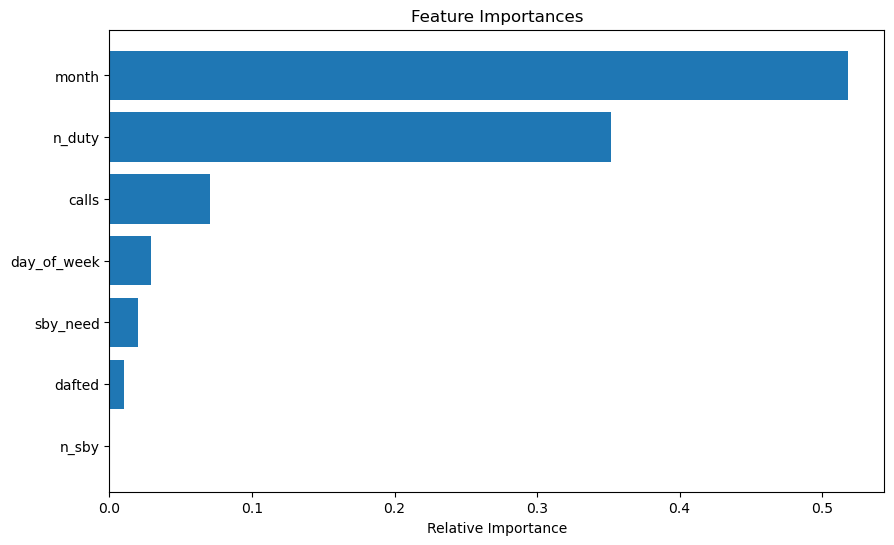

In [7]:
# If further fine-tuning is needed, you can perform hyperparameter tuning on the best model
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    }
    grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'Gradient Boosting':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
# Add similar tuning for other models if needed

# Train the best model with the entire dataset
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

# Final evaluation of the best model
final_mae = mean_absolute_error(y_test, y_pred_best)
final_mse = mean_squared_error(y_test, y_pred_best)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_best)

print(f'Final Evaluation of the Best Model ({best_model_name}):')
print(f'MAE: {final_mae}, MSE: {final_mse}, RMSE: {final_rmse}, R2: {final_r2}')


# Feature Importance for the best model
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()


# Modell mit weniger Features (nur die wichtigsten)

In [12]:
best_model = grid_search.best_estimator_

best_model.fit(X_train, y_train)

X = df[['calls', 'day_of_week', 'month']]
y = df['n_sick']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

best_model.fit(X_train, y_train)

GradientBoostingRegressor(random_state=42)

# Export model

In [13]:
import joblib

# Modell speichern
joblib.dump(best_model, '../../app/models/readiness_model.pkl')
joblib.dump(scaler, '../../app/models/scaler.pkl')

['../../app/models/scaler.pkl']